# AmazonBook — Exploratory Data Analysis (RecSys)

Goal: characterise the user–item bipartite interaction graph before modelling.
Focus areas:
1. Scale, sparsity, density
2. Activity & popularity distributions (long-tail)
3. Imbalance diagnostics: **Gini, entropy, Lorenz, Pareto 80/20**
4. Cold-start quantification
5. Popularity-bias check (train-pop vs test-appearance)
6. Graph-structural view (degree, isolated nodes)

Data format (LightGCN/NGCF): each line = `user_id item1 item2 ...` (positive-only implicit feedback, no features, no timestamps).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

RAW = Path('data/AmazonBook/raw')
plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = True

## 1. Load interactions

In [2]:
def parse(fp):
    rows = []
    with open(fp) as f:
        for line in f:
            p = line.split()
            if not p:
                continue
            u = int(p[0])
            for i in p[1:]:
                rows.append((u, int(i)))
    return np.array(rows, dtype=np.int64)

train = parse(RAW / 'train.txt')
test  = parse(RAW / 'test.txt')

n_users = int(max(train[:,0].max(), test[:,0].max())) + 1
n_items = int(max(train[:,1].max(), test[:,1].max())) + 1
print(f'Users: {n_users:,}  Items: {n_items:,}')
print(f'Train edges: {len(train):,}   Test edges: {len(test):,}')

Users: 52,643  Items: 91,599
Train edges: 2,380,730   Test edges: 603,378


## 2. Sparsity & density

In [3]:
n_train = len(train)
density = n_train / (n_users * n_items)
print(f'Density: {density:.6%}  (fraction of all possible user-item pairs observed)')
print(f'Avg interactions / user: {n_train / n_users:.1f}')
print(f'Avg interactions / item: {n_train / n_items:.1f}')

Density: 0.049372%  (fraction of all possible user-item pairs observed)
Avg interactions / user: 45.2
Avg interactions / item: 26.0


## 3. Activity (per-user) & popularity (per-item) distributions

In [4]:
user_deg = np.bincount(train[:,0], minlength=n_users)
item_deg = np.bincount(train[:,1], minlength=n_items)

def describe(x, name):
    q = np.percentile(x, [50, 90, 95, 99])
    print(f'{name:>12}: min={x.min()} mean={x.mean():.1f} '
          f'median={q[0]:.0f} p90={q[1]:.0f} p95={q[2]:.0f} p99={q[3]:.0f} max={x.max()}')
describe(user_deg, 'user_deg')
describe(item_deg, 'item_deg')

    user_deg: min=16 mean=45.2 median=26 p90=88 p95=132 p99=294 max=10682
    item_deg: min=1 mean=26.0 median=15 p90=52 p95=77 p99=173 max=1741


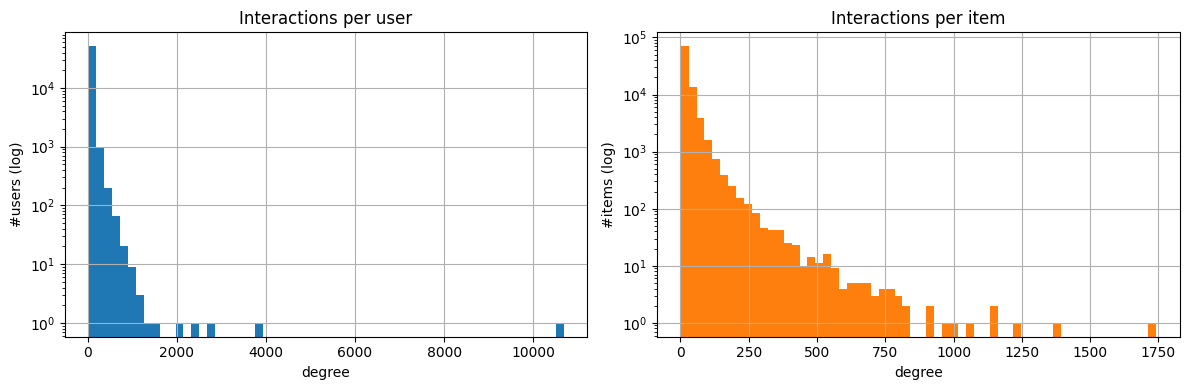

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].hist(user_deg, bins=60); ax[0].set_yscale('log')
ax[0].set_title('Interactions per user'); ax[0].set_xlabel('degree'); ax[0].set_ylabel('#users (log)')
ax[1].hist(item_deg, bins=60, color='tab:orange'); ax[1].set_yscale('log')
ax[1].set_title('Interactions per item'); ax[1].set_xlabel('degree'); ax[1].set_ylabel('#items (log)')
plt.tight_layout(); plt.show()

## 4. Long-tail (item popularity, rank-frequency)

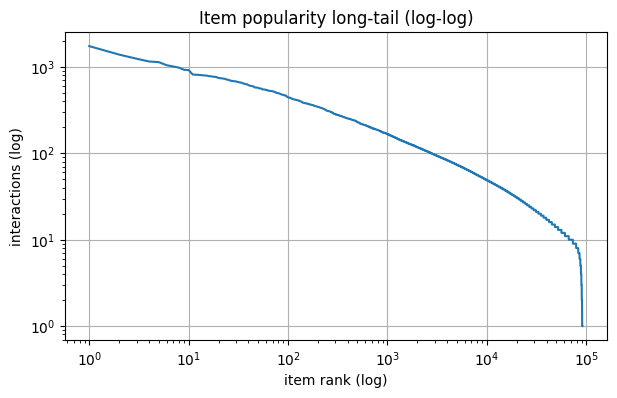

50% of interactions come from top 14,643 items (16.0% of catalogue)
80% of interactions come from top 44,481 items (48.6% of catalogue)


In [6]:
sorted_pop = np.sort(item_deg)[::-1]
plt.figure()
plt.loglog(np.arange(1, len(sorted_pop)+1), sorted_pop)
plt.xlabel('item rank (log)'); plt.ylabel('interactions (log)')
plt.title('Item popularity long-tail (log-log)')
plt.show()

cum = np.cumsum(sorted_pop) / sorted_pop.sum()
for frac in [0.5, 0.8]:
    k = int(np.searchsorted(cum, frac)) + 1
    print(f'{frac:.0%} of interactions come from top {k:,} items '
          f'({k/n_items:.1%} of catalogue)')

## 5. Imbalance diagnostics — Gini, entropy, Lorenz

Item popularity  Gini: 0.488   Norm-entropy: 0.957
User activity    Gini: 0.451   Norm-entropy: 0.959


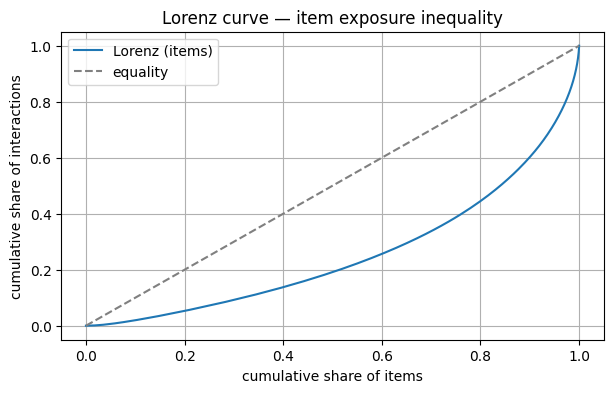

In [7]:
def gini(x):
    x = np.sort(x.astype(np.float64))
    n = len(x); cum = np.cumsum(x)
    return (n + 1 - 2 * (cum / cum[-1]).sum()) / n

def norm_entropy(x):
    p = x[x>0] / x.sum()
    return -(p * np.log(p)).sum() / np.log(len(p))  # 1=uniform, 0=concentrated

print(f'Item popularity  Gini: {gini(item_deg):.3f}   Norm-entropy: {norm_entropy(item_deg):.3f}')
print(f'User activity    Gini: {gini(user_deg):.3f}   Norm-entropy: {norm_entropy(user_deg):.3f}')

# Lorenz curve for item popularity
xs = np.sort(item_deg.astype(np.float64))
lor = np.insert(np.cumsum(xs)/xs.sum(), 0, 0)
p = np.linspace(0, 1, len(lor))
plt.figure()
plt.plot(p, lor, label='Lorenz (items)')
plt.plot([0,1],[0,1],'--',color='gray',label='equality')
plt.xlabel('cumulative share of items'); plt.ylabel('cumulative share of interactions')
plt.title('Lorenz curve — item exposure inequality'); plt.legend(); plt.show()

## 6. Cold-start quantification

In [8]:
for k in [1, 5, 10, 20]:
    cu = (user_deg < k).sum(); ci = (item_deg < k).sum()
    print(f'< {k:>2} interactions:  users={cu:>7,} ({cu/n_users:5.1%})   '
          f'items={ci:>7,} ({ci/n_items:5.1%})')

train_items = set(train[:,1].tolist())
train_users = set(train[:,0].tolist())
test_cold_items = len(set(test[:,1].tolist()) - train_items)
test_cold_users = len(set(test[:,0].tolist()) - train_users)
print(f'\nTest interactions with UNSEEN item: {test_cold_items}')
print(f'Test interactions with UNSEEN user: {test_cold_users}')
print('=> AmazonBook test split has no true cold-start; use content-feature dataset for that story.')

<  1 interactions:  users=      0 ( 0.0%)   items=      0 ( 0.0%)
<  5 interactions:  users=      0 ( 0.0%)   items=  3,183 ( 3.5%)
< 10 interactions:  users=      0 ( 0.0%)   items= 18,279 (20.0%)
< 20 interactions:  users= 13,409 (25.5%)   items= 56,619 (61.8%)



Test interactions with UNSEEN item: 0
Test interactions with UNSEEN user: 0
=> AmazonBook test split has no true cold-start; use content-feature dataset for that story.


## 7. Popularity-bias check (train popularity vs test appearance)

In [9]:
test_item_deg = np.bincount(test[:,1], minlength=n_items)
mask = item_deg > 0
from scipy.stats import spearmanr
rho, _ = spearmanr(item_deg[mask], test_item_deg[mask])
print(f'Spearman corr(train_pop, test_pop): {rho:.3f}')
print('High correlation => benchmark rewards recommending already-popular items (popularity bias).')

# Recall potential by popularity bucket
order = np.argsort(item_deg)[::-1]
head = order[:int(0.05*n_items)]
tail = order[int(0.5*n_items):]
print(f'Head 5% items hold {item_deg[head].sum()/item_deg.sum():.1%} of train interactions')
print(f'Bottom 50% items hold {item_deg[tail].sum()/item_deg.sum():.1%} of train interactions')

Spearman corr(train_pop, test_pop): 0.245
High correlation => benchmark rewards recommending already-popular items (popularity bias).
Head 5% items hold 27.7% of train interactions
Bottom 50% items hold 19.1% of train interactions


## 8. Graph-structural view

In [10]:
iso_items = (item_deg == 0).sum()
iso_users = (user_deg == 0).sum()
print(f'Isolated items (0 train edges): {iso_items:,}')
print(f'Isolated users (0 train edges): {iso_users:,}')
print(f'Bipartite graph: {n_users:,} user-nodes + {n_items:,} item-nodes, {len(train):,} edges')

A = sparse.csr_matrix((np.ones(len(train)), (train[:,0], train[:,1])),
                      shape=(n_users, n_items))
print(f'Adjacency nnz: {A.nnz:,}  shape: {A.shape}')

Isolated items (0 train edges): 0
Isolated users (0 train edges): 0
Bipartite graph: 52,643 user-nodes + 91,599 item-nodes, 2,380,730 edges


Adjacency nnz: 2,380,730  shape: (52643, 91599)


## 9. Summary table (cite these on the KDD slide)

In [11]:
summary = pd.DataFrame({
    'metric': ['users','items','train_edges','test_edges','density',
               'avg_inter_per_user','avg_inter_per_item',
               'item_gini','user_gini','item_norm_entropy',
               'cold_items_lt5','cold_users_lt5'],
    'value': [n_users, n_items, len(train), len(test), density,
              len(train)/n_users, len(train)/n_items,
              gini(item_deg), gini(user_deg), norm_entropy(item_deg),
              int((item_deg<5).sum()), int((user_deg<5).sum())]
})
summary.to_csv('amazonbook_eda_summary.csv', index=False)
summary

,metric,value
0,users,5.264300e+04
1,items,9.159900e+04
2,train_edges,2.380730e+06
3,test_edges,6.033780e+05
4,density,4.937178e-04
5,avg_inter_per_user,4.522406e+01
6,avg_inter_per_item,2.599079e+01
7,item_gini,4.883788e-01
8,user_gini,4.512510e-01
9,item_norm_entropy,9.569390e-01
